![Banner](../images/09_09_banner_rs_image_classification.png)


# Deep Learning for Sentinel-2: CNN, ResNet, EfficientNet, ConvNeXt, ViT and Swin on the GPU

A pixel classifier sees one spectrum at a time.


## Overview

A convolutional neural network (CNN) sees a small **neighbourhood** of pixels, so it can use texture, field edges and spatial context as well as colour. This notebook walks through the complete deep-learning toolbox of `geolattice.rsense.classify.image_classification` on a late-August 2025 **Sentinel-2** scene of the US Corn Belt (10 spectral bands, 10 m), with the 10 m USDA Cropland Data Layer (CDL) as labels, inside the AOI `Corn_belt/aoi.geojson`.

> Which architecture, augmentation and loss work best for classifying $32\times32$ px Sentinel-2 chips, and how well does a chip classifier reproduce a field-level crop map?

* **Data pipeline.** Tensors, chips, datasets and loaders; scene labels from masks; spatial split; class imbalance.
* **Models.** Nine architectures built with `build_cnn` (LeNet, VGG-style, ResNet, EfficientNet, ConvNeXt, ViT, Swin), explained with their mathematics.
* **Training.** Augmentation (`OverheadAugment`, `cutmix`), losses (`get_loss`), `train_model` with AMP, gradient clipping, early stopping, checkpoint and TensorBoard.
* **Evaluation.** Probabilities with test-time augmentation, bootstrap metrics, confusion matrix, a wall-to-wall map and an error analysis.

GPU recommended; the experiments shrink automatically on a CPU.


## Core concepts

### Learning objectives

1. Convert Sentinel-2 reflectance and CDL labels on a common grid into chips, datasets and loaders, and derive scene labels from masks.
2. Split spatially without leakage, normalise with training statistics only, and handle class imbalance with class weights.
3. Explain the building blocks and mathematics of LeNet, VGG, ResNet, EfficientNet, ConvNeXt, ViT and Swin, and compare their size, receptive field and cost.
4. Use overhead-imagery augmentation, CutMix and robust losses.
5. Train with `train_model` (optimiser, schedule, AMP, clipping, early stopping, checkpoint, TensorBoard) and reload the checkpoint.
6. Evaluate honestly: bootstrap intervals, mean ± SD over seeds, a pixel-level check of the map against the CDL.

### Contents

1. Setup: libraries, device and data paths
2. From rasters to tensors: Sentinel-2 stack, CDL labels, chips, datasets and loaders
3. Scene labels from masks, spatial split and class imbalance
4. CNN architectures and the mathematics behind them
5. Data augmentation for overhead imagery: dihedral transforms and CutMix
6. Loss functions: cross-entropy, weighted, focal and label smoothing
7. Training loop and optimisation with `train_model`
8. Final model: early stopping, checkpoint and TensorBoard
9. Inference and evaluation
10. Summary of the experiments
11. Interpretation, caveats and recommended recipe


### Task and evaluation design

**Data:** Sentinel-2 L2A scene `2025_08_20250826` (10 bands, 10 m) · CDL 2025 at 10 m (labels) · AOI `Corn_belt/aoi.geojson`.

**Task.** *Scene (chip) classification*: each $32\times32$ px chip (320 m $\times$ 320 m, 10 spectral bands) receives one label, the **majority CDL class** inside the chip. This is the scene-classification formulation used for benchmark data sets such as EuroSAT; it differs from pixel-wise classification (earlier notebooks) and from segmentation.

**Honest evaluation.** Neighbouring chips overlap (stride 16 px) and share spatial autocorrelation. We therefore split by **256 px spatial blocks** (`group_split`), so that no block contributes chips to two splits, and verify this with `check_split_isolation`. The test blocks come from the same scene, so the numbers describe *spatial* generalisation inside the AOI, not transfer to a new date or region.

| Step | Functions |
|---|---|
| Tensors, datasets, loaders | `set_seed`, `read_class_dict`, `rgb_mask_to_index`, `chips_from_folder`, `extract_chips`, `ChipDataset`, `as_loader` |
| Scene labels, imbalance | majority class per chip, `class_weights` |
| Architectures | `build_cnn`, `count_parameters`, `receptive_field` |
| Augmentation | `OverheadAugment`, `cutmix` |
| Losses | `get_loss` |
| Training | `train_model`, `load_checkpoint` |
| Inference, evaluation | `predict_proba_batches`, `predict_chip_map`, `classification_report` |


## Setup: libraries, device and data paths

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings, tempfile  # JSON, timing, warnings and temporary folders
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
import numpy as np, pandas as pd, xarray as xr, rioxarray  # arrays, tables, labelled rasters and raster I/O
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours
import torch  # PyTorch: the networks
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # the data folder, from the notebook folder or the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
S2 = DATA / "Sentinel_2" / "2025_08_20250826"  # the 26 August 2025 Sentinel-2 scene
CDL_PATH = DATA / "CDL" / "10_m" / "CDL_2025_10m.tif"  # the 2025 CDL at 10 m
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon
for p in (S2, CDL_PATH, AOI_PATH):  # every input ...
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("torch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (reduce EPOCHS / SEEDS below)")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
SCALE = 1.0 if DEVICE == "cuda" else 0.4   # CPU users: shrink the experiments
# epochs and seeds of the experiments (fewer on a CPU)
EPOCHS_ARCH, EPOCHS_ABL, SEEDS = (15, 12, [0, 1, 2]) if DEVICE == "cuda" else (4, 4, [0])


torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## From rasters to tensors: Sentinel-2 stack, CDL labels, chips, datasets and loaders

### Reproducible runs with `set_seed`
`set_seed(seed, deterministic=False)` seeds Python, NumPy and PyTorch (CPU and CUDA). `deterministic=True` additionally forces deterministic cuDNN kernels (slower, bit-for-bit repeatable). We use the fast mode and instead repeat experiments over several seeds, reporting mean $\pm$ SD, because differences of a few tenths of a percent are within seed noise.

### Sentinel-2 reflectance stack on a common 10 m grid
The scene has four 10 m bands and six 20 m bands. The 20 m bands are bilinearly resampled to the 10 m grid. Digital numbers (DN) are converted to surface reflectance with the L2A scale factor

$$\rho = 10^{-4}\,\mathrm{DN}.$$

(The STAC metadata of newer processing baselines also lists an offset of $-0.1$; the DNs in these files are already offset-corrected - the 1st/50th/99th red percentiles are 147/261/1304, which would be negative reflectance with the offset - so only the scale is applied.) Pixels flagged by the scene classification layer (SCL: no data, saturated, cloud shadow, cloud, cirrus) become `NaN`. `extract_chips(..., max_nan_fraction=0.0)` later drops every chip that touches such a pixel.


In [2]:
# the ten Sentinel-2 bands
BANDS = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
ref = rioxarray.open_rasterio(S2 / "red.tif").squeeze(drop=True)  # the 10 m red band as the reference grid
layers = []  # one array per band
for b in BANDS:  # each band
    a = rioxarray.open_rasterio(S2 / f"{b}.tif").squeeze(drop=True)  # read it
    if a.shape != ref.shape:  # a 20 m band ...
        a = a.rio.reproject_match(ref, resampling=1)          # bilinear: 20 m -> 10 m
    layers.append(a.astype("float32"))  # as float32
dn = xr.concat(layers, dim="band").assign_coords(band=BANDS)  # stacked along "band"
# scene classification layer on the 10 m grid
scl = rioxarray.open_rasterio(S2 / "scl.tif").squeeze(drop=True).rio.reproject_match(ref, resampling=0).values
bad = np.isin(scl, [0, 1, 3, 8, 9, 10, 11])  # no data, saturated, shadow, cloud, cirrus and snow
bad_da = xr.DataArray(bad, dims=("y", "x"), coords={"y": dn.y, "x": dn.x})  # as a DataArray
refl = (dn.where(dn > 0) * 1e-4).where(~bad_da)  # reflectance, with flagged pixels set to missing
refl.name = "reflectance"  # its name
# size, CRS and masked share
print(f"stack {tuple(refl.shape)} (band, y, x) | CRS {refl.rio.crs} | masked (cloud/shadow/nodata) {bad.mean():.2%}")

stack (10, 2911, 3032) (band, y, x) | CRS EPSG:32615 | masked (cloud/shadow/nodata) 0.22%


### CDL labels recoded to six land-cover classes
The 10 m CDL raster is reprojected (nearest neighbour, labels must never be interpolated) from EPSG:5070 to the Sentinel-2 grid and recoded to six classes. Code 0 (background) becomes $-1$ and is ignored.


         class  pixel share
          Corn       0.5265
      Soybeans       0.3643
 Grass/pasture       0.0393
     Developed       0.0447
Wetland/forest       0.0141
         Other       0.0112


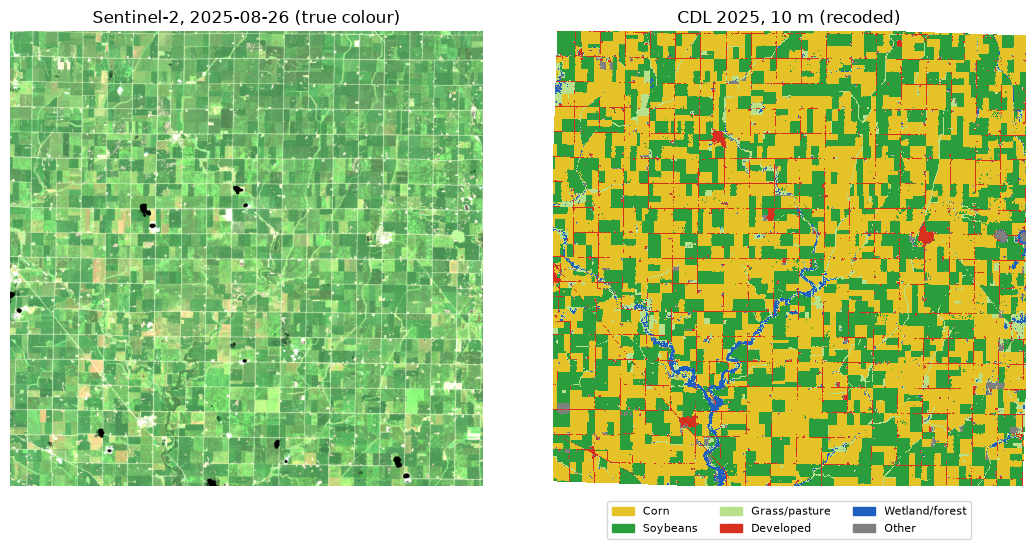

In [3]:
# CDL on the 10 m grid (nearest neighbour)
cdl = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True).rio.reproject_match(ref, resampling=0)
code_map = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4}  # CDL code -> class id
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # their colour map
raw = cdl.values.astype(int)  # CDL codes as integers
lab = np.full(raw.shape, 5, "int16")  # everything else is "Other" (5)
for k, v in code_map.items():  # the mapped codes ...
    lab[raw == k] = v  # ... get their class
lab[raw == 0] = -1  # no data
share = pd.Series(lab[lab >= 0]).value_counts(normalize=True).sort_index()  # share of each class
# as a small table
print(pd.DataFrame({"class": CLASSES, "pixel share": share.reindex(range(K)).round(4).values}).to_string(index=False))

def rgb(a, lo=0.0, hi=0.07):  # true-colour image for display
    im = np.moveaxis(a.sel(band=["red", "green", "blue"]).values, 0, -1)  # red, green, blue with bands last
    return np.clip((np.nan_to_num(im) - lo) / (hi - lo), 0, 1) ** 0.8  # stretch, clip and brighten slightly

fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))  # two panels
ax[0].imshow(rgb(refl)); ax[0].set_title("Sentinel-2, 2025-08-26 (true colour)")  # true colour
# recoded CDL
ax[1].imshow(np.where(lab < 0, np.nan, lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
ax[1].set_title("CDL 2025, 10 m (recoded)")  # title
for a in ax: a.axis("off")  # no axes
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES,  # class legend
             loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.13))
plt.tight_layout(); plt.show()  # arrange and draw

### Cutting 32 × 32 px image chips with `extract_chips`
`extract_chips(image, samples, size=, max_nan_fraction=)` cuts $(C, s, s)$ windows centred on map coordinates. We lay a regular grid of centres with **stride 16 px** (50 % overlap) wholly inside **256 px blocks** (the block id is the grouping variable for the split). The same function applied to the label raster returns *mask chips*, from which the scene label is derived in the *From rasters to tensors: Sentinel-2 stack, CDL labels, chips, datasets and loaders* section.


In [4]:
SIZE, STRIDE, BLOCK = 32, 16, 256  # 32 px chips, 16 px stride, 256 px blocks
nb = min(refl.shape[1], refl.shape[2]) // BLOCK            # 11 x 11 blocks
xs, ys = refl.x.values, refl.y.values  # pixel-centre coordinates
pts, bid, rc = [], [], []  # chip centres, block ids and positions
for bi in range(nb):  # every block row ...
    for bj in range(nb):  # ... and column
        for r in range(bi * BLOCK, (bi + 1) * BLOCK - SIZE + 1, STRIDE):  # chip rows in the block
            for c in range(bj * BLOCK, (bj + 1) * BLOCK - SIZE + 1, STRIDE):  # chip columns in the block
                # centre, block id and position of the chip
                pts.append((xs[c + SIZE // 2], ys[r + SIZE // 2])); bid.append(bi * nb + bj); rc.append((r, c))
pts, bid, rc = np.array(pts), np.array(bid), np.array(rc)  # as arrays

t0 = time.time()  # start the timer
# cut the 10-band chips, dropping any chip with a missing pixel
Xall, _, xy = ic.extract_chips(refl, pts, size=SIZE, max_nan_fraction=0.0)
# extract_chips drops chips with NaNs: find which candidate centres survived
cand = {(round(float(a), 3), round(float(b), 3)): i for i, (a, b) in enumerate(pts)}
# index of each kept chip among the candidates
keep = np.array([cand[(round(float(a), 3), round(float(b), 3))] for a, b in np.asarray(xy)[:, :2]])
lab_da = refl.isel(band=[0]).copy(data=lab[None].astype("float32"))  # the label map as a one-band raster
Mall, _, _ = ic.extract_chips(lab_da, pts, size=SIZE, max_nan_fraction=1.0)  # label chips at the same centres
Mall = Mall[keep, 0].astype(int)                           # (N, 32, 32) mask chips
bid, rc = bid[keep], rc[keep]  # block ids and positions of the kept chips
# counts, time and memory
print(f"candidate chips {len(pts):,} -> clean chips {len(Xall):,} ({time.time()-t0:.1f}s) | "
      f"chip tensor {Xall.shape} float32 = {Xall.nbytes/1e9:.2f} GB | mask chips {Mall.shape}")

candidate chips 27,225 -> clean chips 26,995 (0.9s) | chip tensor (26995, 10, 32, 32) float32 = 1.11 GB | mask chips (26995, 32, 32)


### Image/mask folders: `read_class_dict`, `rgb_mask_to_index`, `chips_from_folder`
Many public benchmarks (DeepGlobe, LoveDA, ...) ship as paired `*_sat.jpg` + `*_mask.png` files, with the class legend as a CSV of `name,r,g,b`. GeoLattice reads that layout directly. To show it with our data, we **write** such a pair for two $512\times512$ px windows (RGB image, colour-coded mask) and read it back. `rgb_mask_to_index` thresholds each channel at 128, so mask colours must be corners of the RGB cube; black is "unknown" and is ignored.


In [5]:
from PIL import Image  # write PNG and JPEG files
demo = Path(tempfile.mkdtemp(prefix="s2_folder_"))  # a temporary folder in the image-folder layout
# class -> RGB colour of the mask
corner = {0: (255, 255, 0), 1: (0, 255, 0), 2: (0, 255, 255), 3: (255, 0, 0), 4: (0, 0, 255), 5: (255, 0, 255)}
# the class table as CSV
pd.DataFrame([(n, *corner[i]) for i, n in enumerate(CLASSES)], columns=["name", "r", "g", "b"]).to_csv(demo / "classes.csv", index=False)
img8 = (rgb(refl) * 255).astype("uint8")  # the true-colour image as 8-bit
for k, (r0, c0) in enumerate([(300, 300), (1500, 1800)]):  # two 512 x 512 windows
    Image.fromarray(img8[r0:r0 + 512, c0:c0 + 512]).save(demo / f"{k}_sat.jpg", quality=95)  # save the image
    m = np.zeros((512, 512, 3), "uint8")  # an empty RGB mask
    for i, col in corner.items():  # each class ...
        m[lab[r0:r0 + 512, c0:c0 + 512] == i] = col  # ... painted in its colour
    Image.fromarray(m).save(demo / f"{k}_mask.png")  # save the mask

names, colors = ic.read_class_dict(demo / "classes.csv")  # read the class table back
print("class dict:", names, colors[0])  # names and the first colour
mask_img = np.array(Image.open(demo / "0_mask.png"))  # the first mask
idx = ic.rgb_mask_to_index(mask_img, colors)  # RGB colours -> class ids
print("rgb_mask_to_index round-trip equals recoded CDL:",  # the round trip reproduces the labels
      bool((idx[lab[300:812, 300:812] >= 0] == lab[300:812, 300:812][lab[300:812, 300:812] >= 0]).all()))
# cut 128 px chips from the folder
chips_f, masks_f, stems = ic.chips_from_folder(demo, colors=colors, size=128, stride=128)
# chip and mask shapes, value range and sources
print("chips_from_folder:", chips_f.shape, chips_f.min().round(2), "-", chips_f.max().round(2), "| masks", masks_f.shape, "| sources", sorted(set(stems)))

class dict: ['Corn', 'Soybeans', 'Grass/pasture', 'Developed', 'Wetland/forest', 'Other'] (255, 255, 0)
rgb_mask_to_index round-trip equals recoded CDL: True
chips_from_folder: (32, 3, 128, 128) 0.0 - 1.0 | masks (32, 128, 128) | sources ['0_sat', '1_sat']


### Datasets and mini-batch loaders: `ChipDataset` and `as_loader`
`ChipDataset(images, targets, normalizer=, transform=)` is a map-style dataset yielding `{"image", "label"}` dicts (or `"mask"` for dense targets). It applies a **fitted** `Normalizer` per band and replaces `NaN` by 0. `as_loader` wraps it in a seeded `DataLoader` (reproducible shuffling). The key rule: **fit the normaliser on the training chips only**; validation and test chips are transformed with the training mean and standard deviation, otherwise test statistics leak into training.

First we need the scene labels and the split.


## Scene labels from masks, spatial split and class imbalance

The label of a chip is the **majority class** of its mask chip,

$$y_i=\arg\max_{k}\;n_{ik},\qquad n_{ik}=\#\{\text{pixels of chip }i\text{ with class }k\},\qquad p_i=\frac{\max_k n_{ik}}{\sum_k n_{ik}}\;(\text{purity}).$$

Mixed chips (low purity $p_i$) are inherently ambiguous: a chip that is 40 % corn and 40 % soybeans cannot be classified reliably from reflectance alone. We keep chips with $p_i\ge 0.6$ and with less than 20 % background pixels, and report how much this matters.


chips kept: 22,000 of 26,995 (81.5%) | median purity 0.92


         class  chips  share
          Corn  13201 0.6000
      Soybeans   8381 0.3810
 Grass/pasture    203 0.0092
     Developed     86 0.0039
Wetland/forest     97 0.0044
         Other     32 0.0015


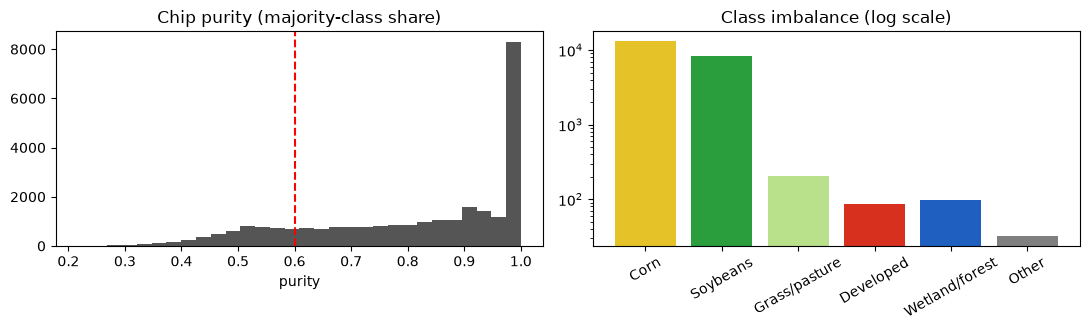

In [6]:
valid = (Mall >= 0)  # labelled pixels of every chip
counts = np.stack([(Mall == k).sum((1, 2)) for k in range(K)], 1)        # (N, K)
y_all = counts.argmax(1)  # majority class of each chip
purity = counts.max(1) / np.maximum(valid.sum((1, 2)), 1)  # share of that class
ok = (valid.mean((1, 2)) >= 0.8) & (purity >= 0.6)  # chips at least 80 % labelled and 60 % pure
# how many are kept
print(f"chips kept: {ok.sum():,} of {len(ok):,} ({ok.mean():.1%}) | median purity {np.median(purity[ok]):.2f}")
X, y, groups = Xall[ok], y_all[ok], bid[ok]  # chips, labels and block ids
chip_rc = rc[ok]  # their positions
# chips per class
print(pd.DataFrame({"class": CLASSES, "chips": np.bincount(y, minlength=K), "share": (np.bincount(y, minlength=K) / len(y)).round(4)}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))  # two panels
ax[0].hist(purity, bins=30, color="#555"); ax[0].axvline(0.6, color="r", ls="--"); ax[0].set_title("Chip purity (majority-class share)"); ax[0].set_xlabel("purity")
# chips per class on a log scale
ax[1].bar(CLASSES, np.bincount(y, minlength=K), color=COLORS); ax[1].set_yscale("log"); ax[1].set_title("Class imbalance (log scale)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()  # arrange and draw

### Spatial-block split and training-only normalisation
`group_split(groups, test_size=, val_size=)` assigns *whole blocks* to train/validation/test. `check_split_isolation` raises if any block appears in two splits. Neighbouring blocks still touch, so a very small leakage along block edges remains; this is why the *Training loop and optimisation with `train_model`* section reports uncertainty and why the earlier notebooks add a geographic hold-out.


train 13,156 | val 4,453 | test 4,391 chips (73/24/24 blocks) - isolation check passed
                train   val  test
Corn             7858  2860  2483
Soybeans         4983  1527  1871
Grass/pasture     165    23    15
Developed          65    20     1
Wetland/forest     72     4    21
Other              13    19     0


batch: {'image': ((128, 10, 32, 32), 'torch.float32'), 'label': ((128,), 'torch.int64')} | train mean/std per band after z-score: 0.006458694580942392 1.0254820585250854


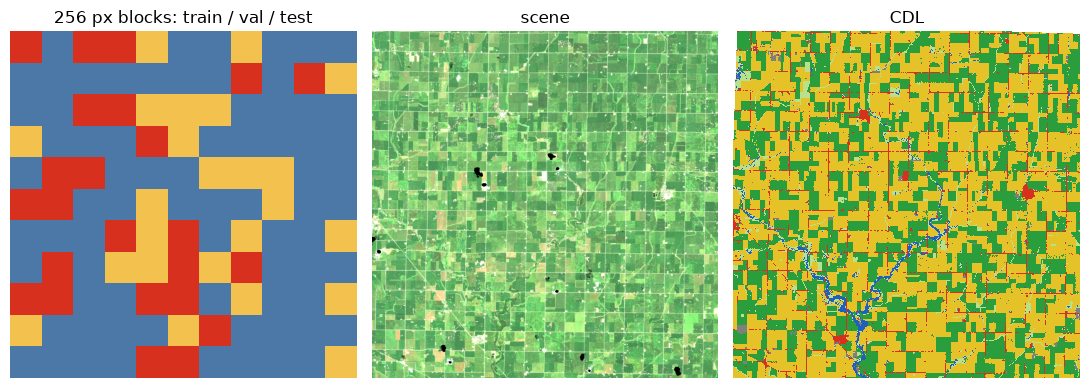

In [7]:
sp = ic.group_split(groups, test_size=0.2, val_size=0.2, seed=SEED)  # 60 / 20 / 20 split by whole blocks
tr, va, te = sp.train, sp.val, sp.test  # the three index sets
# no block in two splits
ic.check_split_isolation(train=np.unique(groups[tr]), val=np.unique(groups[va]), test=np.unique(groups[te]))
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} chips "  # split sizes and block counts
      f"({len(np.unique(groups[tr]))}/{len(np.unique(groups[va]))}/{len(np.unique(groups[te]))} blocks) - isolation check passed")
# chips per class and split
print(pd.DataFrame({s: np.bincount(y[i], minlength=K) for s, i in [("train", tr), ("val", va), ("test", te)]}, index=CLASSES))

norm = ic.Normalizer("zscore").fit(X[tr], band_axis=1)       # training chips only
# chip dataset of indices idx with the training normaliser
mk = lambda idx, tf=None: ic.ChipDataset(X[idx], y[idx], normalizer=norm, transform=tf)
ds_tr, ds_va, ds_te = mk(tr), mk(va), mk(te)  # the three datasets
ld_tr = ic.as_loader(ds_tr, 128, shuffle=True, seed=SEED)  # shuffled training batches
# validation and test batches
ld_va, ld_te = ic.as_loader(ds_va, 256, shuffle=False), ic.as_loader(ds_te, 256, shuffle=False)
b = next(iter(ld_tr))  # one training batch
# its tensors and their scaled statistics
print("batch:", {k: (tuple(v.shape), str(v.dtype)) for k, v in b.items()},
      "| train mean/std per band after z-score:", float(b["image"].mean()), float(b["image"].std()))

fig, ax = plt.subplots(1, 3, figsize=(11, 4))  # three panels
bsplit = np.zeros(nb * nb)  # split of every block
# train 0, validation 1, test 2
bsplit[np.unique(groups[tr])] = 0; bsplit[np.unique(groups[va])] = 1; bsplit[np.unique(groups[te])] = 2
missing = np.setdiff1d(np.arange(nb * nb), np.unique(groups)); bsplit[missing] = np.nan  # blocks without chips
ax[0].imshow(bsplit.reshape(nb, nb), cmap=ListedColormap(["#4c78a8", "#f2c14e", "#d7301f"]), interpolation="nearest")
ax[0].set_title("256 px blocks: train / val / test")  # title
ax[1].imshow(rgb(refl)[:nb * BLOCK, :nb * BLOCK]); ax[1].set_title("scene")  # the scene
# the labels
ax[2].imshow(np.where(lab < 0, np.nan, lab)[:nb * BLOCK, :nb * BLOCK], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("CDL")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

### Class weights for imbalanced classes
With classes of very different frequency, plain cross-entropy is dominated by the majority class. `class_weights` converts counts $n_k$ into weights with three recipes (normalised to mean 1):

$$w_k^{\text{inverse}}\propto\frac1{n_k},\qquad w_k^{\sqrt{\ }}\propto\frac1{\sqrt{n_k}},\qquad w_k^{\text{effective}}\propto\frac{1-\beta}{1-\beta^{\,n_k}}\ \ (\text{Cui et al., 2019; }\beta=0.999).$$

The "effective number of samples" $E_n=(1-\beta^{n})/(1-\beta)$ accounts for the overlap between samples of the same class: more samples add less and less new information.


In [8]:
# three class-weighting rules
W = {m: ic.class_weights(y[tr], num_classes=K, method=m) for m in ("inverse", "sqrt_inverse", "effective")}
print(pd.DataFrame(W, index=CLASSES).round(3))  # the weights per class

                inverse  sqrt_inverse  effective
Corn              0.007         0.109      0.052
Soybeans          0.011         0.137      0.052
Grass/pasture     0.323         0.750      0.339
Developed         0.820         1.195      0.820
Wetland/forest    0.740         1.136      0.743
Other             4.099         2.673      3.995


## CNN architectures and the mathematics behind them

`build_cnn(arch, in_channels, num_classes, pretrained=False, first_conv="mean", dropout=None, **kwargs)` returns a model whose **first layer is rebuilt for $C=10$ spectral bands**. With `pretrained=True` the RGB weights of the first convolution are averaged (`first_conv="mean"`) and replicated over the extra bands, a standard way to reuse ImageNet features for multispectral data. Here we train from scratch, which is common for small chips where the ImageNet prior is less useful. For ViT, `image_size` must match the chip size (`image_size=32`).

| Family | `arch` | Core idea |
|---|---|---|
| LeNet | `lenet` | two conv + pool stages, three fully connected layers |
| VGG-style | `vgg_small`, `simple_cnn`, `vgg11/13/16_bn` | stacked $3\times3$ convolutions + batch norm |
| ResNet | `resnet18/34/50/101` | residual (skip) connections |
| EfficientNet | `efficientnet_b0..b2`, `efficientnet_v2_s` | depth-wise separable MBConv + squeeze-excitation, compound scaling |
| ConvNeXt | `convnext_tiny/small/base` | modernised ResNet: $7\times7$ depth-wise conv, LayerNorm, inverted bottleneck |
| ViT | `vit_b_16/32` | patches $\to$ tokens $\to$ global self-attention |
| Swin | `swin_t/s`, `swin_v2_t` | shifted-window attention, hierarchical stages |

### Shared notation
A convolution with kernel $k$, stride $s$, padding $p$ maps an $H\times W$ map to

$$H'=\Big\lfloor\frac{H+2p-k}{s}+1\Big\rfloor,\qquad Z_o(i,j)=b_o+\sum_{c=1}^{C_{in}}\sum_{u,v=0}^{k-1}W_{o,c}(u,v)\,A_c(si+u-p,\,sj+v-p),$$

with $k^2C_{in}C_{out}+C_{out}$ parameters. **Batch normalisation** standardises each channel over the mini-batch, $\hat z=(z-\mu_B)/\sqrt{\sigma_B^2+\epsilon}$, then applies a learned scale and shift, $y=\gamma\hat z+\beta$. Activations are $\mathrm{ReLU}(z)=\max(0,z)$ or $\mathrm{GELU}(z)=z\,\Phi(z)$. Every classifier ends with global average pooling $\bar a_c=\frac1{HW}\sum_{i,j}A_c(i,j)$, a linear layer $\mathbf s=W\bar{\mathbf a}+\mathbf b$ and the softmax $p_k=e^{s_k}/\sum_m e^{s_m}$.


### LeNet (`lenet`)
LeNet-5 style: $\;[\text{conv}\,5{\times}5\,(C{\to}6)\to\text{ReLU}\to\text{pool}]\to[\text{conv}\,5{\times}5\,(6{\to}16)\to\text{ReLU}\to\text{pool}]\to\text{FC}\,400{\to}120\to84\to K$.

For the $32\times32$ chip: $32\xrightarrow{\text{conv},p=2}32\xrightarrow{\text{pool}}16\xrightarrow{\text{conv}}12\xrightarrow{\text{pool}}6$, then adaptive pooling to $5\times5$ gives $16\cdot5\cdot5=400$ features. Parameters with $C=10$, $K=6$:

$$(5^2\cdot10\cdot6+6)+(5^2\cdot6\cdot16+16)+(400\cdot120+120)+(120\cdot84+84)+(84\cdot6+6)=62{,}716 .$$

Two pooling stages give a receptive field of only 16 px: it cannot "see" the whole chip through convolution alone (coverage 0.5; see *Parameters and receptive field*). The large fully connected layer, not the convolutions, holds 98 % of the parameters.


### VGG-style networks (`vgg_small`, `simple_cnn`, `vgg11/13/16_bn`)
VGG replaces large filters by **stacks of $3\times3$ convolutions**. Two stacked $3\times3$ layers see a $5\times5$ neighbourhood, three see $7\times7$, but with fewer parameters and more non-linearities: $2\cdot(3^2C^2)=18C^2<25C^2$ for one $5\times5$ layer. A block is

$$\mathrm{Block}(\mathbf X)=\mathrm{MaxPool}_2\Big(\mathrm{ReLU}\big(\mathrm{BN}(W_2*\mathrm{ReLU}(\mathrm{BN}(W_1*\mathbf X)))\big)\Big),$$

with the channel width doubling per block. `vgg_small` uses widths $(32,64,128)$ and `simple_cnn` widths $(16,32)$, each followed by global average pooling, dropout and one linear layer. Because global average pooling replaces the huge VGG fully connected head, they are tiny: 290 k and 18 k parameters. The receptive field of `vgg_small` is 36 px, i.e. it covers the whole $32\times32$ chip.


### ResNet (`resnet18/34/50/101`)
Plain deep networks become hard to optimise because gradients vanish. ResNet adds an **identity shortcut** so each block learns a *residual*:

$$\mathbf y=\mathcal F(\mathbf x;\{W_i\})+\mathbf x,\qquad \frac{\partial\mathbf y}{\partial\mathbf x}=\mathbf I+\frac{\partial\mathcal F}{\partial\mathbf x}.$$

The identity term gives gradients a direct path to early layers. The *basic block* (ResNet-18/34) is $\mathcal F=\mathrm{BN}(W_2*\mathrm{ReLU}(\mathrm{BN}(W_1*\mathbf x)))$ with two $3\times3$ convolutions, followed by ReLU after the addition. ResNet-50/101 use a *bottleneck* $1{\times}1\,(C\to C/4)\to3{\times}3\to1{\times}1\,(C/4\to C)$ to cut the cost. When the shape changes, the shortcut is a strided $1\times1$ convolution $W_s\mathbf x$. ResNet-18 has 8 basic blocks in 4 stages (widths 64, 128, 256, 512; 11.2 M parameters), ResNet-34 has 16 (21.3 M). The ImageNet stem (stride-2 $7\times7$ convolution + max pool) downsamples by 4 immediately, so on a 32 px chip the last stage works on a $1\times1$ map: the network is very deep for such small inputs, which explains why ResNet-34 is not better than ResNet-18 here.


### EfficientNet (`efficientnet_b0..b2`, `efficientnet_v2_s`)
EfficientNet is built from **MBConv** blocks: an inverted bottleneck with a **depth-wise separable convolution** and **squeeze-and-excitation** (SE) channel attention. A standard $k\times k$ convolution costs $k^2C_{in}C_{out}$ multiply-adds per pixel; the separable version splits it into a depth-wise $k\times k$ convolution (one filter per channel) and a point-wise $1\times1$ convolution:

$$\underbrace{k^2C_{in}}_{\text{depth-wise}}+\underbrace{C_{in}C_{out}}_{\text{point-wise}}\;\ll\;k^2C_{in}C_{out}\quad\Big(\text{ratio }\tfrac1{C_{out}}+\tfrac1{k^2}\Big).$$

An MBConv block expands channels by a factor $t$ ($1{\times}1$), applies the depth-wise convolution, rescales channels by the SE gate $\mathbf g=\sigma\big(W_2\,\mathrm{SiLU}(W_1\,\bar{\mathbf a})\big)$ with $\bar{\mathbf a}$ the global average of each channel, projects back ($1{\times}1$) and adds a residual connection when shapes match. SiLU is $z\,\sigma(z)$. **Compound scaling** grows depth $d=\alpha^\phi$, width $w=\beta^\phi$ and resolution $r=\gamma^\phi$ together under $\alpha\beta^2\gamma^2\approx2$, so that the cost roughly doubles per unit of $\phi$. B0 has only 4 M parameters but is slower per step than ResNet-18 because depth-wise convolutions use the GPU poorly.


### ConvNeXt (`convnext_tiny/small/base`)
ConvNeXt modernises a ResNet with design choices borrowed from transformers: a "patchify" stem (stride-4 $4\times4$ convolution), a **$7\times7$ depth-wise convolution**, **LayerNorm** instead of batch norm, an **inverted bottleneck** MLP with GELU, and residual connections. One block is

$$\mathbf y=\mathbf x+\gamma\odot W_2\,\mathrm{GELU}\big(W_1\,\mathrm{LN}(\mathrm{DWConv}_{7\times7}(\mathbf x))\big),\qquad W_1:C\to4C,\; W_2:4C\to C,$$

where $\gamma$ is a learnable per-channel layer scale. LayerNorm normalises over the channel dimension of every pixel, $\hat z=(z-\mu)/\sqrt{\sigma^2+\epsilon}$, so it does not depend on the batch size. ConvNeXt-tiny has stages of depth $(3,3,9,3)$ and widths $(96,192,384,768)$ ($27.8$ M parameters). It matches transformers in large-data regimes but needs more data than a small chip set offers.


### Vision Transformer (`vit_b_16`, `vit_b_32`)
ViT drops convolution almost entirely. The image is cut into non-overlapping $P\times P$ patches, each flattened and linearly projected to a $d$-dimensional **token**; a learnable class token is prepended and position embeddings $\mathbf E_{pos}$ are added:

$$\mathbf z_0=[\mathbf x_{cls};\,\mathbf x_1W_E;\dots;\mathbf x_nW_E]+\mathbf E_{pos},\qquad n=(H/P)^2.$$

Each of $L$ encoder layers applies multi-head **self-attention** (MSA) and an MLP, each with a pre-LayerNorm and a residual connection:

$$\mathbf z'_\ell=\mathbf z_{\ell-1}+\mathrm{MSA}(\mathrm{LN}(\mathbf z_{\ell-1})),\qquad \mathbf z_\ell=\mathbf z'_\ell+\mathrm{MLP}(\mathrm{LN}(\mathbf z'_\ell)),$$

$$\mathrm{Attn}(\mathbf Q,\mathbf K,\mathbf V)=\mathrm{softmax}\!\Big(\frac{\mathbf Q\mathbf K^{\top}}{\sqrt{d_k}}\Big)\mathbf V,\quad \mathbf Q=\mathbf ZW_Q,\ \mathbf K=\mathbf ZW_K,\ \mathbf V=\mathbf ZW_V .$$

The class token after the last layer feeds the linear classifier. Every token attends to every other token, so the receptive field is global from the first layer, but there is no built-in locality or translation equivariance, so ViT needs a lot of data. With $P=16$ a $32\times32$ chip yields only $n=4$ tokens, and ViT-B has 87 M parameters: it is the heaviest and the least suited model here.


### Swin Transformer (`swin_t/s`, `swin_v2_t`)
Swin keeps the transformer but makes it hierarchical and local. Attention is computed **within non-overlapping windows** of $M\times M$ tokens, so the cost is linear in the number of tokens $N$ instead of quadratic:

$$\Omega(\mathrm{MSA})=4NC^2+2N^2C,\qquad \Omega(\mathrm{W\text{-}MSA})=4NC^2+2M^2NC .$$

Successive layers **shift** the window grid by $\lfloor M/2\rfloor$ so information flows across windows. Attention gets a learned relative position bias $B$:

$$\mathrm{Attn}=\mathrm{softmax}\!\Big(\frac{\mathbf Q\mathbf K^{\top}}{\sqrt{d_k}}+B\Big)\mathbf V .$$

Between stages, **patch merging** concatenates $2\times2$ neighbouring tokens and projects $4C\to2C$, halving the resolution like a CNN pooling layer. Swin-T uses a $4\times4$ patch embedding, depths $(2,2,6,2)$ and $27.5$ M parameters. The hierarchy gives it the multi-scale features of a CNN; on a 32 px chip, however, the token grid is only $8\times8$ and shrinks to $1\times1$.


### What the architectures share
* **Convolutional nets** (LeNet, VGG, ResNet, EfficientNet, ConvNeXt) carry the *prior* that nearby pixels matter and that features repeat across the image (translation equivariance, $f(T\mathbf x)=Tf(\mathbf x)$). That prior is a strong advantage with 13 k small training chips.
* **Residual connections** (ResNet, EfficientNet, ConvNeXt, ViT, Swin) make deep stacks trainable.
* **Normalisation** is batch norm in VGG/ResNet/EfficientNet and LayerNorm in ConvNeXt/ViT/Swin.
* **Transformers** trade the convolutional prior for global attention and need more data or pre-training.
* Cost grows from 18 k parameters (`simple_cnn`) to 87 M (`vit_b_16`), so more parameters are only worthwhile if the task is hard.


### Parameters and receptive field
`count_parameters(model)` counts trainable weights. `receptive_field(model, input_size=)` follows the conv/pool path and returns the receptive field $r$ and the jump $j$ (output stride) by the recursion

$$r_{l}=r_{l-1}+(k_l-1)\,j_{l-1},\qquad j_l=j_{l-1}\,s_l,$$

and the **coverage** $\min(1,r/\text{input size})$. A coverage below 1 means the final convolutional features cannot see the whole chip (LeNet: 16 of 32 px). Receptive fields far above 32 px (ResNet-18: 1,891 px) simply mean that the last layers see the whole padded chip. For transformers the value reflects only the patch embedding; attention is global by construction, so it is not meaningful there.


In [9]:
# the nine architectures to compare
ARCHS = [("lenet", {}), ("simple_cnn", {}), ("vgg_small", {}), ("resnet18", {}), ("resnet34", {}),
         ("efficientnet_b0", {}), ("convnext_tiny", {}), ("vit_b_16", {"image_size": 32}), ("swin_t", {})]
rows = []  # one row per architecture
for a, kw in ARCHS:  # each one
    m = ic.build_cnn(a, in_channels=len(BANDS), num_classes=K, **kw)  # build it for ten bands and six classes
    try:
        rf = ic.receptive_field(m, input_size=SIZE)  # theoretical receptive field on a 32 px chip
        rf_s, cov = int(rf["rf"]), rf["coverage"]  # its size and coverage of the chip
    except Exception:
        rf_s, cov = None, None  # not available for this architecture
    # size and receptive field
    rows.append({"arch": a, "parameters": ic.count_parameters(m), "receptive field (px)": rf_s, "coverage of chip": cov})
arch_tab = pd.DataFrame(rows).set_index("arch")  # as a table
print(arch_tab.to_string())  # show it
x = torch.randn(4, len(BANDS), SIZE, SIZE)  # a random batch of four chips
# every model returns (4, 6) scores
print("forward pass OK for all:", all(ic.build_cnn(a, in_channels=len(BANDS), num_classes=K, **kw).eval()(x).shape == (4, K) for a, kw in ARCHS))

                 parameters  receptive field (px)  coverage of chip
arch                                                               
lenet                 62716                    16             0.500
simple_cnn            17958                    16             0.500
vgg_small            290246                    36             1.000
resnet18           11201542                  1891             1.000
resnet34           21309702                  4083             1.000
efficientnet_b0     4017250                   851             1.000
convnext_tiny      27835494                  1688             1.000
vit_b_16           87032070                    16             0.500
swin_t             27534720                     4             0.125


forward pass OK for all: True


## Data augmentation for overhead imagery: dihedral transforms and CutMix

Satellite images have **no intrinsic "up"**: a field rotated by 90° is still a valid field. All 8 elements of the dihedral group $D_4$ (4 rotations $\times$ optional flip) are therefore label-preserving, in contrast to street-level photographs where only horizontal flips are. `OverheadAugment(dihedral=True, brightness, contrast, noise, crop, p, seed)` is used as the `transform` of `ChipDataset`; radiometric jitter (`brightness`, `contrast`, `noise`) should be used with care on calibrated reflectance.

**CutMix** (Yun et al., 2019) pastes a rectangular patch of chip $B$ into chip $A$ and mixes the labels in proportion to the patch area:

$$\tilde{\mathbf x}=\mathbf M\odot\mathbf x_A+(1-\mathbf M)\odot\mathbf x_B,\qquad \tilde y=\lambda\,y_A+(1-\lambda)\,y_B,\quad \lambda\sim\mathrm{Beta}(\alpha,\alpha),$$

with $\lambda$ adjusted to the exact pixel area of the paste. The loss becomes $\lambda\,\mathcal L(f(\tilde{\mathbf x}),y_A)+(1-\lambda)\,\mathcal L(f(\tilde{\mathbf x}),y_B)$. `cutmix(images, targets, alpha, rng)` returns `(mixed, y_a, y_b, lam)`; `train_model(..., cutmix_prob=p)` applies it internally.


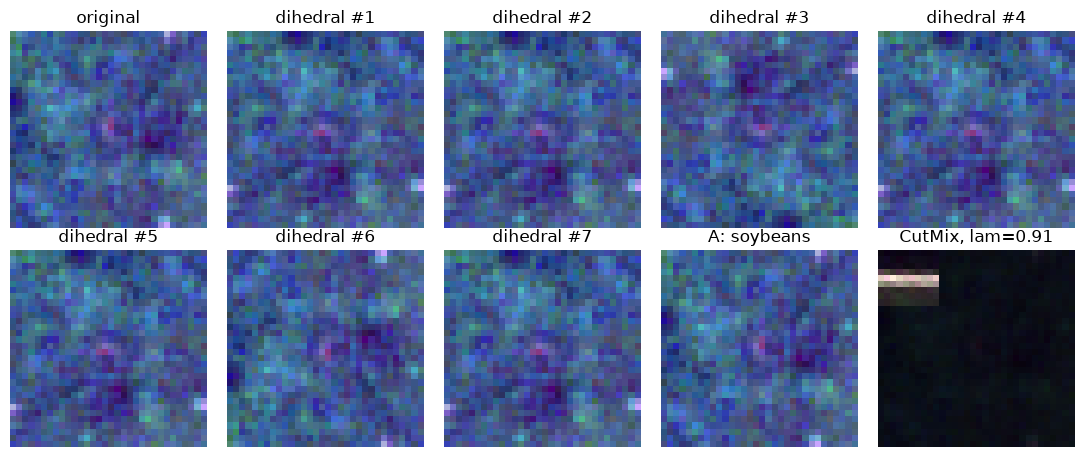

In [10]:
i0 = int(np.where(y[tr] == 1)[0][5])  # a soybean training chip
aug = ic.OverheadAugment(dihedral=True, p=1.0, seed=1)  # the eight rotations and flips
base = ic.ChipDataset(X[tr][i0:i0 + 1], y[tr][i0:i0 + 1], normalizer=norm)  # that chip, normalised
img0 = base[0]["image"]  # its tensor
red_nir_red = [2, 1, 0]  # display bands
def show(t):   # tensor -> displayable RGB
    # stretch to 0-1, bands last
    a = t.numpy()[red_nir_red]; a = (a - a.min()) / (a.max() - a.min() + 1e-9); return np.moveaxis(a, 0, -1)
fig, ax = plt.subplots(2, 5, figsize=(11, 4.6))  # the panels
ax[0, 0].imshow(show(img0)); ax[0, 0].set_title("original")  # the original
for k in range(1, 8):  # seven random dihedral versions
    t, _ = aug(img0.clone(), None); a = ax.flat[k]; a.imshow(show(t)); a.set_title(f"dihedral #{k}")
# cutmix demo
rng = np.random.default_rng(0)
# a soybean and a corn chip
xb = torch.stack([base[0]["image"], ic.ChipDataset(X[tr][[int(np.where(y[tr] == 0)[0][3])]], y[tr][[0]], normalizer=norm)[0]["image"]])
mixed, ya, yb, lam = ic.cutmix(xb.clone(), torch.tensor([1, 0]), alpha=1.0, rng=rng)  # CutMix of the two
# chip A and the mixed chip
ax.flat[8].imshow(show(xb[0])); ax.flat[8].set_title("A: soybeans"); ax.flat[9].imshow(show(mixed[0])); ax.flat[9].set_title(f"CutMix, lam={float(lam):.2f}")
for a in ax.flat: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## Loss functions: cross-entropy, weighted, focal and label smoothing

For logits $\mathbf z$ and softmax probabilities $p_k=e^{z_k}/\sum_j e^{z_j}$ with one-hot target $y$:

* **Cross-entropy:** $\mathcal L_{\text{CE}}=-\log p_y$.
* **Weighted CE:** $\mathcal L=-w_y\log p_y$ with $w$ from `class_weights`; minority errors cost more.
* **Label smoothing** $\varepsilon$: replace the one-hot target by $(1-\varepsilon)\,\mathbb 1_y+\varepsilon/K$, giving $\mathcal L=-(1-\varepsilon)\log p_y-\frac{\varepsilon}{K}\sum_k\log p_k$. It prevents over-confident logits and helps when the labels are noisy; CDL is itself a model product with about 5-15 % class-specific error, so some label noise is certain.
* **Focal loss** (Lin et al., 2017): $\mathcal L_{\text{focal}}=-\alpha_y\,(1-p_y)^{\gamma}\log p_y$. The modulating factor $(1-p_y)^\gamma$ down-weights easy examples ($p_y\to1$) so that training focuses on hard, often minority-class examples; $\gamma=2$ is the usual choice.

All losses accept $(N,C)$ logits with $(N,)$ targets. Quick numerical check on one batch:


{'ce': 3.1363, 'weighted_ce': 3.1055, 'focal (g=2)': 2.8576, 'focal + weights': 2.6772, 'label smoothing 0.1': 3.1391}


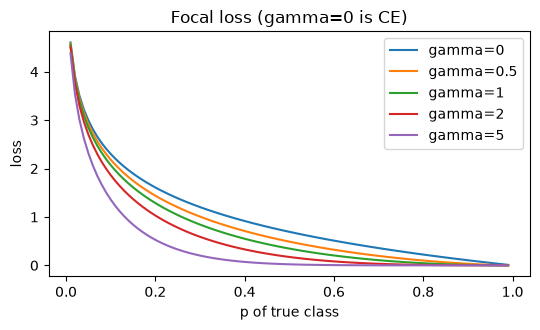

In [11]:
zb = torch.randn(256, K) * 2; yb_ = torch.randint(0, K, (256,))  # random scores and labels for 256 samples
cw = W["sqrt_inverse"]  # square-root inverse class weights
losses = {"ce": ic.get_loss("ce"), "weighted_ce": ic.get_loss("weighted_ce", class_weights=cw),  # five losses
          "focal (g=2)": ic.get_loss("focal", gamma=2.0), "focal + weights": ic.get_loss("focal", gamma=2.0, class_weights=cw),
          "label smoothing 0.1": ic.get_loss("ce", label_smoothing=0.1)}
print({k: round(float(f(zb, yb_)), 4) for k, f in losses.items()})  # loss of each on the same batch
p = torch.linspace(0.01, 0.99, 99)  # probabilities of the true class
plt.figure(figsize=(5.5, 3.4))  # one panel
# focal loss for several gamma values
for g in (0, 0.5, 1, 2, 5): plt.plot(p, -(1 - p) ** g * torch.log(p), label=f"gamma={g}")
# labels, title, legend and draw
plt.xlabel("p of true class"); plt.ylabel("loss"); plt.title("Focal loss (gamma=0 is CE)"); plt.legend(); plt.tight_layout(); plt.show()

## Training loop and optimisation with `train_model`

`train_model(model, train_loader, val_loader, task="classification", epochs, loss, optimizer, lr, weight_decay, scheduler, precision, grad_clip, early_stopping, monitor, checkpoint, seed, num_classes, cutmix_prob, logger, log_dir, ...)` is an explicit PyTorch loop that implements:

* **AdamW** (decoupled weight decay): $\theta\leftarrow\theta-\eta\Big(\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta\Big)$ with first/second moment estimates $m_t,v_t$;
* **Cosine schedule:** $\eta_t=\tfrac12\eta_0\big(1+\cos(\pi t/T)\big)$, annealing the learning rate smoothly to zero; `onecycle`, `step` and `plateau` are alternatives;
* **Mixed precision** (`precision="16"` with gradient scaling, or `"bf16"`): forward/backward in half precision on the GPU for speed and memory, master weights in float32;
* **Gradient clipping:** $\mathbf g\leftarrow\mathbf g\cdot\min\!\big(1,\,c/\lVert\mathbf g\rVert_2\big)$ with $c$ = `grad_clip`;
* **Early stopping** on `monitor` (`val_loss` or `val_score` = accuracy) with patience, and **restoring of the best weights**;
* **Checkpoint** of the best state and **logging** to TensorBoard (or W&B, MLflow, or any callable).

It returns a history dict (`train_loss`, `val_loss`, `val_score`, `lr`). The helper below wraps one experiment: it builds the datasets, trains, and scores the test blocks. Model selection uses the **validation** set only; the test set is touched once per run for reporting.


In [12]:
def prob_to_report(P, yt, n_boot=0):  # accuracy report from class probabilities
    # most probable class against the labels
    return ic.classification_report(yt, P.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=n_boot, seed=0)

# train one model and score it
def fit(arch, *, seed=0, epochs=12, loss="ce", aug=None, cutmix=0.0, lr=1e-3, wd=1e-4, kw=None, precision="16",
        cw=None, label_smoothing=0.0, early=None, checkpoint=None, logger=None, log_dir=None, tta=False):
    ic.set_seed(seed)  # same initial weights for a given seed
    # optional rotation and flip augmentation
    tf = None if aug is None else ic.OverheadAugment(dihedral=True, p=1.0, seed=seed)
    dtr = mk(tr, tf)  # training dataset
    ltr = ic.as_loader(dtr, 128, shuffle=True, seed=seed)  # shuffled training batches
    model = ic.build_cnn(arch, in_channels=len(BANDS), num_classes=K, **(kw or {}))  # the network
    lf = ic.get_loss(loss, class_weights=cw, label_smoothing=label_smoothing)  # the loss
    t0 = time.time()  # start the timer
    # the GeoLattice training loop
    hist = ic.train_model(model, ltr, ld_va, task="classification", epochs=epochs, loss=lf, optimizer="adamw", lr=lr,
                          weight_decay=wd, scheduler="cosine", precision=precision if DEVICE == "cuda" else "32", grad_clip=1.0,
                          early_stopping=early, monitor="val_score", checkpoint=checkpoint, seed=seed, num_classes=K,
                          cutmix_prob=cutmix, logger=logger, log_dir=log_dir, device=DEVICE, verbose=False)
    sec = time.time() - t0  # training time
    Pv = ic.predict_proba_batches(model, ld_va, device=DEVICE)  # validation probabilities
    # test probabilities (optionally with test-time augmentation)
    Pt = ic.predict_proba_batches(model, ld_te, device=DEVICE, tta=tta)
    # model, history, time and scores
    return dict(model=model, hist=hist, sec=sec, val_acc=float((Pv.argmax(1) == y[va]).mean()),
                test_acc=float((Pt.argmax(1) == y[te]).mean()), P=Pt)

def agg(df, by):  # mean scores per group
    # validation and test accuracy, spread, time and runs
    g = df.groupby(by).agg(val_acc=("val_acc", "mean"), test_mean=("test_acc", "mean"), test_sd=("test_acc", "std"),
                           sec=("sec", "mean"), n=("test_acc", "size"))
    return g  # the table

### Benchmarking the nine architectures under one recipe
Every architecture is trained with the **same** recipe (AdamW, lr $10^{-3}$, cosine, AMP, grad-clip 1, plain CE, no augmentation) for a fixed number of epochs. One seed per architecture; the seeds are repeated for the ablations in the *Augmentation and loss ablations on ResNet-18 (mean ± SD over seeds)* section. Parameters and receptive field are from the *CNN architectures and the mathematics behind them* section.


In [13]:
lr_by = {"vit_b_16": 3e-4, "swin_t": 3e-4, "convnext_tiny": 5e-4}     # transformers/ConvNeXt prefer smaller lr
res_arch = {}  # results of each architecture
rows = []  # one row per architecture
for a, kw in ARCHS:  # each one
    r = fit(a, seed=0, epochs=EPOCHS_ARCH, lr=lr_by.get(a, 1e-3), kw=kw)  # train it
    res_arch[a] = r  # keep it
    # size, speed and accuracy
    rows.append({"arch": a, "parameters": arch_tab.loc[a, "parameters"], "receptive field": arch_tab.loc[a, "receptive field (px)"],
                 "sec/epoch": r["sec"] / EPOCHS_ARCH, "best val acc": max(r["hist"]["val_score"]), "test acc": r["test_acc"]})
    # progress line
    print(f"{a:16s} val {rows[-1]['best val acc']:.4f}  test {r['test_acc']:.4f}  ({r['sec']:.0f}s)")
arch_res = pd.DataFrame(rows).set_index("arch").round(4)  # as a table
arch_res  # show it

lenet            val 0.9908  test 0.9982  (14s)


simple_cnn       val 0.9942  test 0.9993  (10s)


vgg_small        val 0.9946  test 0.9991  (12s)


resnet18         val 0.9939  test 0.9984  (18s)


resnet34         val 0.9926  test 0.9984  (27s)


efficientnet_b0  val 0.9915  test 0.9989  (39s)


convnext_tiny    val 0.9928  test 0.9977  (41s)


vit_b_16         val 0.9888  test 0.9948  (75s)


swin_t           val 0.9921  test 0.9980  (79s)


,parameters,receptive field,sec/epoch,best val acc,test acc
arch,,,,,
lenet,62716,16,0.9252,0.9908,0.9982
simple_cnn,17958,16,0.6649,0.9942,0.9993
vgg_small,290246,36,0.7857,0.9946,0.9991
resnet18,11201542,1891,1.2140,0.9939,0.9984
resnet34,21309702,4083,1.8291,0.9926,0.9984
efficientnet_b0,4017250,851,2.6110,0.9915,0.9989
convnext_tiny,27835494,1688,2.7267,0.9928,0.9977
vit_b_16,87032070,16,4.9940,0.9888,0.9948
swin_t,27534720,4,5.2600,0.9921,0.9980


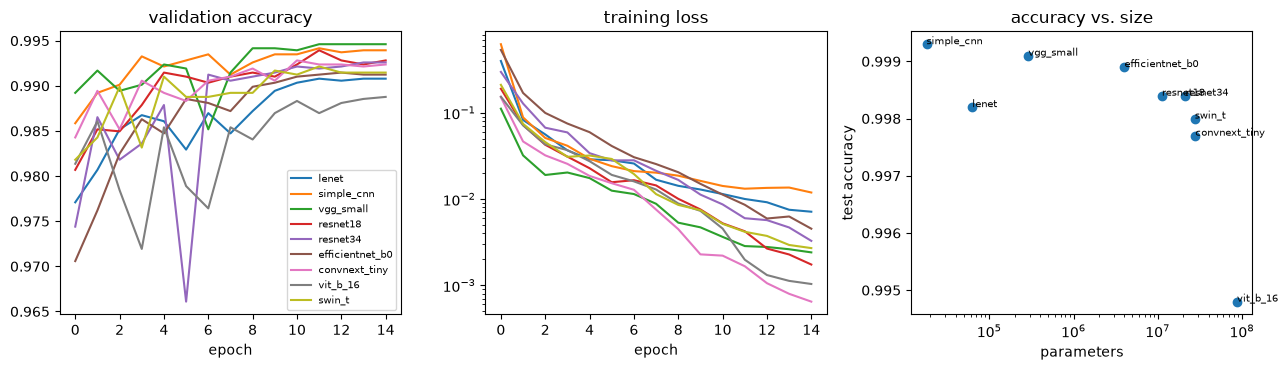

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))  # three panels
for a, r in res_arch.items():  # each architecture
    ax[0].plot(r["hist"]["val_score"], label=a)  # its validation accuracy
    ax[1].plot(r["hist"]["train_loss"], label=a)  # its training loss
# titles, log scale and legend
ax[0].set_title("validation accuracy"); ax[1].set_title("training loss"); ax[1].set_yscale("log"); ax[0].legend(fontsize=7)
for a in ax[:2]: a.set_xlabel("epoch")  # epoch axes
ax[2].scatter(arch_res["parameters"], arch_res["test acc"], c="C0")  # accuracy against size
# architecture names
for a, r in arch_res.iterrows(): ax[2].annotate(a, (r["parameters"], r["test acc"]), fontsize=7)
# log axis, labels and title
ax[2].set_xscale("log"); ax[2].set_xlabel("parameters"); ax[2].set_ylabel("test accuracy"); ax[2].set_title("accuracy vs. size")
plt.tight_layout(); plt.show()  # arrange and draw

### Augmentation and loss ablations on ResNet-18 (mean ± SD over seeds)
We now fix **ResNet-18** (a good accuracy/cost compromise on this data) and vary one ingredient at a time, over seeds $\{0,1,2\}$ and report mean $\pm$ SD of test accuracy. Differences smaller than about one SD should not be interpreted as real.


In [15]:
CW = W["sqrt_inverse"]  # the class weights used below
configs = {  # eight training variants of ResNet-18
    "baseline (CE)":              dict(),
    "+ OverheadAugment":          dict(aug=True),
    "+ CutMix (p=0.5)":           dict(cutmix=0.5),
    "+ Aug + CutMix":             dict(aug=True, cutmix=0.5),
    "weighted CE (sqrt-inv.)":    dict(loss="weighted_ce", cw=CW),
    "focal (gamma=2)":            dict(loss="focal"),
    "focal + weights":            dict(loss="focal", cw=CW),
    "label smoothing 0.1":        dict(label_smoothing=0.1),
}
rows = []  # one row per run
for name, cfg in configs.items():  # each variant
    for s in SEEDS:  # each seed
        # the augmentation flag -> an OverheadAugment class
        c = dict(cfg); c["aug"] = ic.OverheadAugment if c.pop("aug", False) else None
        r = fit("resnet18", seed=s, epochs=EPOCHS_ABL, **c)  # train it
        rrep = prob_to_report(r["P"], y[te])  # test report
        # the scores
        rows.append(dict(config=name, seed=s, val_acc=r["val_acc"], test_acc=r["test_acc"], macro_f1=rrep["macro_f1"], sec=r["sec"]))
    print(name, "done")  # progress
abl = pd.DataFrame(rows)  # as a table
# mean and spread per variant
tab = abl.groupby("config", sort=False).agg(val_acc=("val_acc", "mean"), test_acc=("test_acc", "mean"), test_sd=("test_acc", "std"),
                                            macro_f1=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"), sec=("sec", "mean")).round(4)
tab  # show it

baseline (CE) done


+ OverheadAugment done


+ CutMix (p=0.5) done


+ Aug + CutMix done


weighted CE (sqrt-inv.) done


focal (gamma=2) done


focal + weights done


label smoothing 0.1 done


,val_acc,test_acc,test_sd,macro_f1,macro_f1_sd,sec
config,,,,,,
baseline (CE),0.9931,0.9983,0.0005,0.9652,0.0218,14.6803
+ OverheadAugment,0.9939,0.9984,0.0005,0.9768,0.0018,16.9489
+ CutMix (p=0.5),0.9944,0.9995,0.0002,0.9901,0.0038,15.0160
+ Aug + CutMix,0.9951,0.9991,0.0002,0.9779,0.0102,17.2164
weighted CE (sqrt-inv.),0.9923,0.9976,0.0001,0.9124,0.0487,14.7212
focal (gamma=2),0.9935,0.9986,0.0003,0.9334,0.0413,15.3890
focal + weights,0.9907,0.9978,0.0006,0.9142,0.0365,15.2976
label smoothing 0.1,0.9927,0.9986,0.0000,0.9606,0.0120,15.0706


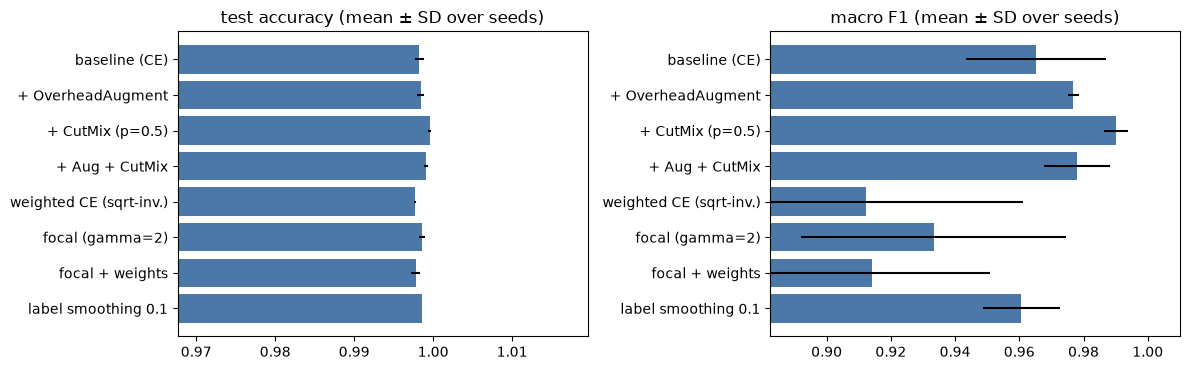

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))  # two panels
# test accuracy and macro F1
for a, col, t in [(ax[0], "test_acc", "test accuracy"), (ax[1], "macro_f1", "macro F1")]:
    g = abl.groupby("config", sort=False)[col]  # runs grouped by variant
    a.barh(range(len(g.mean())), g.mean(), xerr=g.std(), color="#4c78a8"); a.set_yticks(range(len(g.mean()))); a.set_yticklabels(g.mean().index)
    # limits, title, top-to-bottom order
    a.set_xlim(g.mean().min() - 0.03, g.mean().max() + 0.02); a.set_title(f"{t} (mean ± SD over seeds)"); a.invert_yaxis()
plt.tight_layout(); plt.show()  # arrange and draw

## Final model: early stopping, checkpoint and TensorBoard

We train the final model with everything switched on: AdamW + cosine schedule, mixed precision, gradient clipping, **early stopping** (patience 6 on validation accuracy), best-weights **checkpoint** and **TensorBoard** logging (guarded in case it is not installed). The best configuration in the *Augmentation and loss ablations on ResNet-18 (mean ± SD over seeds)* section is selected on the **validation** accuracy (not the test accuracy) and the final training is longer than the ablation runs.


config selected on validation accuracy: + Aug + CutMix


I0000 00:00:1795637723.007340   89198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795637723.217782   89198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795637726.199732   89198 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


stopped after 30 epochs | best val acc 0.9957 | test acc 0.9993 | checkpoint resnet18_best.pt (44.9 MB) | logger: tensorboard
TensorBoard event files: ['events.out.tfevents.1795637726.zia207-ThinkPad-P16-Gen-1.89198.0']


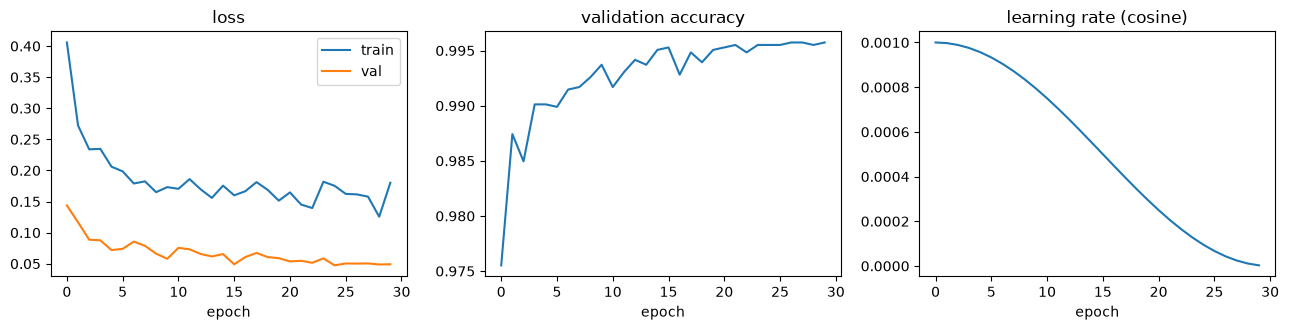

In [17]:
# the variant with the best validation accuracy
best_cfg = abl.groupby("config", sort=False)["val_acc"].mean().idxmax()
print("config selected on validation accuracy:", best_cfg)  # report it
# its settings
cfg = dict(configs[best_cfg]); cfg["aug"] = ic.OverheadAugment if cfg.pop("aug", False) else None

try:
    import tensorboard  # noqa
    LOGGER = "tensorboard"  # TensorBoard is installed
except ImportError:
    LOGGER = None  # no logger
OUT = Path(tempfile.mkdtemp(prefix="adv_cnn_"))  # a temporary output folder
CKPT = OUT / "resnet18_best.pt"  # the checkpoint file
# train the final model with early stopping and a checkpoint
final = fit("resnet18", seed=SEED, epochs=int(30 * SCALE) if DEVICE == "cuda" else 6, early=6, checkpoint=CKPT,
            logger=LOGGER, log_dir=str(OUT / "tb"), **cfg)
h = final["hist"]  # its history
# epochs, scores and checkpoint size
print(f"stopped after {len(h['val_score'])} epochs | best val acc {max(h['val_score']):.4f} | test acc {final['test_acc']:.4f} | "
      f"checkpoint {CKPT.name} ({CKPT.stat().st_size/1e6:.1f} MB) | logger: {LOGGER}")
# the TensorBoard files
print("TensorBoard event files:", sorted(p.name for p in (OUT / "tb").rglob("events*"))[:2] if LOGGER else "n/a")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))  # three panels
# loss curves
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("loss"); ax[0].legend()
# validation accuracy and learning rate
ax[1].plot(h["val_score"]); ax[1].set_title("validation accuracy"); ax[2].plot(h["lr"]); ax[2].set_title("learning rate (cosine)")
for a in ax: a.set_xlabel("epoch")  # epoch axes
plt.tight_layout(); plt.show()  # arrange and draw

### Restoring the model with `load_checkpoint`
`load_checkpoint(model, path)` loads the saved weights into a **freshly built** model of the same architecture and returns `(model, missing_keys)`. A correct round trip reproduces the predictions exactly.


In [18]:
fresh = ic.build_cnn("resnet18", in_channels=len(BANDS), num_classes=K)  # a fresh ResNet-18
fresh, missing = ic.load_checkpoint(fresh, CKPT)  # load the saved weights
P_fresh = ic.predict_proba_batches(fresh, ld_te, device=DEVICE)  # test probabilities of the reloaded model
# missing keys and the largest difference
print("load_state_dict:", missing, "| max |p_trained - p_reloaded| =", float(np.abs(P_fresh - final["P"]).max()))

load_state_dict: <All keys matched successfully> | max |p_trained - p_reloaded| = 0.0


## Inference and evaluation: probabilities, TTA, bootstrap metrics and confusion matrix

* `predict_proba_batches(model, data, tta=False)` returns softmax probabilities in batches; `tta=True` averages the 8 dihedral transforms (**test-time augmentation**), $\bar p=\frac18\sum_{g\in D_4}p(g\cdot\mathbf x)$, the inference counterpart of `OverheadAugment`.
* `classification_report(y_true, y_pred, labels, class_names, n_boot)` gives overall accuracy, Cohen's $\kappa$, macro-F1, per-class precision/recall/F1 and a **bootstrap confidence interval** (resampling test chips with replacement).

Because chips in a block are spatially autocorrelated, the bootstrap interval is somewhat optimistic; the SD over seeds in the *Training loop and optimisation with `train_model`* section is a complementary uncertainty measure.


In [19]:
P_plain = ic.predict_proba_batches(final["model"], ld_te, device=DEVICE)  # test probabilities without TTA
# and with the eight rotations and flips averaged
P_tta = ic.predict_proba_batches(final["model"], ld_te, device=DEVICE, tta=True)
yt = y[te]  # test labels
# accuracy report of the TTA predictions
rep = ic.classification_report(yt, P_tta.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=300, seed=0)
# both accuracies
print(f"plain  OA {(P_plain.argmax(1) == yt).mean():.4f} | TTA (8 dihedral) OA {(P_tta.argmax(1) == yt).mean():.4f}")
# headline scores
print(f"overall accuracy {rep['overall_accuracy']:.4f} | kappa {rep['kappa']:.4f} | macro-F1 {rep['macro_f1']:.4f} | n = {rep['n']:,}")
# bootstrap intervals
print("bootstrap 95% CI:", {k: tuple(round(float(x), 4) for x in v) for k, v in rep["ci"].items()} if isinstance(rep["ci"], dict) else rep["ci"])
pc = rep["per_class"]  # per-class scores
print(pd.DataFrame(pc).round(3) if not isinstance(pc, pd.DataFrame) else pc.round(3))  # show them

plain  OA 0.9993 | TTA (8 dihedral) OA 0.9993
overall accuracy 0.9993 | kappa 0.9986 | macro-F1 0.9856 | n = 4,391
bootstrap 95% CI: {'oa': (0.9984, 1.0), 'kappa': (0.9968, 1.0), 'macro_f1': (0.9572, 1.0)}
                precision  recall     f1  support  f1_ci_low  f1_ci_high
Corn                  1.0   1.000  1.000     2483      0.999         1.0
Soybeans              1.0   0.999  1.000     1871      0.999         1.0
Grass/pasture         1.0   0.867  0.929       15      0.812         1.0
Developed             1.0   1.000  1.000        1      1.000         1.0
Wetland/forest        1.0   1.000  1.000       21      1.000         1.0
Other                 0.0     NaN    NaN        0        NaN         NaN


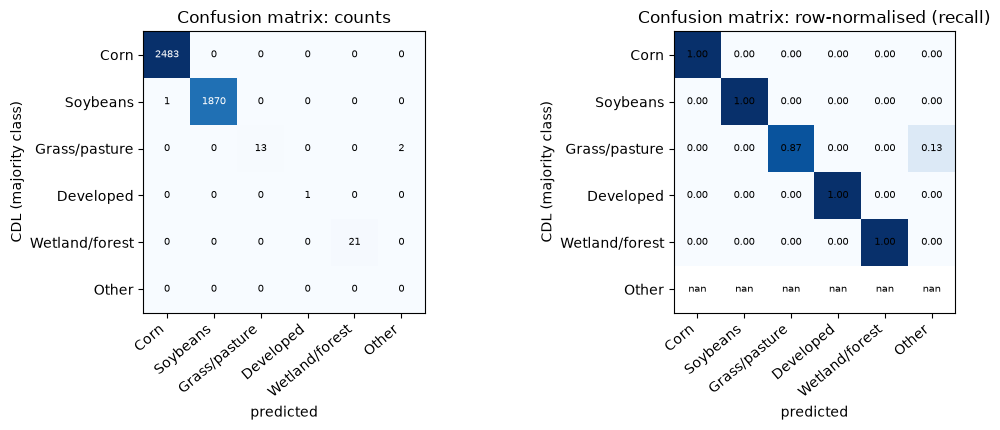

In [20]:
cmx = np.asarray(rep["confusion_matrix"])  # the confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))  # two panels
# counts and row shares
for a, M, t, f in [(ax[0], cmx, "counts", "d"), (ax[1], cmx / cmx.sum(1, keepdims=True), "row-normalised (recall)", ".2f")]:
    # the matrix with class names
    a.imshow(M, cmap="Blues"); a.set_xticks(range(K)); a.set_yticks(range(K)); a.set_xticklabels(CLASSES, rotation=40, ha="right"); a.set_yticklabels(CLASSES)
    for i in range(K):  # every cell ...
        # ... with its value
        for j in range(K): a.text(j, i, format(M[i, j], f), ha="center", va="center", fontsize=7, color="w" if M[i, j] > M.max() / 2 else "k")
    # title and axis labels
    a.set_title(f"Confusion matrix: {t}"); a.set_xlabel("predicted"); a.set_ylabel("CDL (majority class)")
plt.tight_layout(); plt.show()  # arrange and draw

### Wall-to-wall prediction map with `predict_chip_map`
`predict_chip_map(model, image, size=, stride=, normalizer=, batch_size=)` slides the chip classifier over a georeferenced image and assigns each pixel the class of the chip whose centre is nearest (stride 8 here; each pixel then comes from a chip centred within 4 px). Chips with `NaN` (cloud) get nodata $-1$. The normaliser is the one fitted on the training chips. We evaluate the map **only on pixels inside test blocks**, comparing with the original 10 m CDL pixels (not the chip majority labels), which is the number a map user actually experiences.


map (2816, 2816) in 14s
pixel-level OA on test blocks vs. CDL: 0.8843 | kappa 0.7920 | macro-F1 0.4901 | pixels 1,558,911


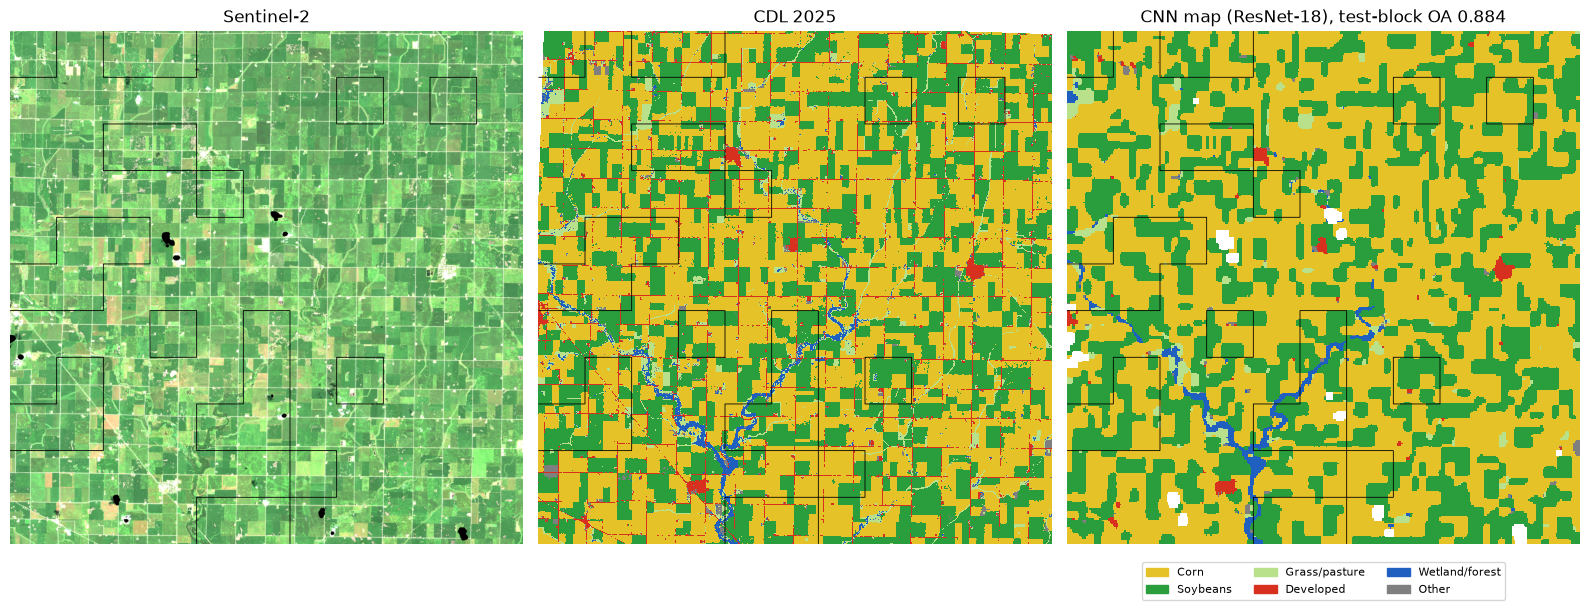

In [21]:
sub = refl.isel(y=slice(0, nb * BLOCK), x=slice(0, nb * BLOCK))  # the area covered by blocks
t0 = time.time()  # start the timer
# class map from a sliding 32 px window
pm = ic.predict_chip_map(final["model"], sub, size=SIZE, stride=8, normalizer=norm, batch_size=512, device=DEVICE)
pred = pm.values.astype(int); print(f"map {pred.shape} in {time.time()-t0:.0f}s")  # as integers; time
blk = np.kron(np.arange(nb * nb).reshape(nb, nb), np.ones((BLOCK, BLOCK), int))  # block id of every pixel
# pixels in test blocks; reference labels
is_te = np.isin(blk, np.unique(groups[te])); ref_l = lab[:nb * BLOCK, :nb * BLOCK]
m = is_te & (pred >= 0) & (ref_l >= 0)  # test pixels with a prediction and a label
oa_px = (pred[m] == ref_l[m]).mean()  # pixel accuracy
# pixel accuracy report
rep_px = ic.classification_report(ref_l[m], pred[m], labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=0)
# the scores
print(f"pixel-level OA on test blocks vs. CDL: {oa_px:.4f} | kappa {rep_px['kappa']:.4f} | macro-F1 {rep_px['macro_f1']:.4f} | pixels {m.sum():,}")

fig, ax = plt.subplots(1, 3, figsize=(16, 5.6))  # three panels
sh = lambda a: np.where(a < 0, np.nan, a)  # negative ids as missing
ax[0].imshow(rgb(sub)); ax[0].set_title("Sentinel-2")  # the scene
# the CDL
ax[1].imshow(sh(ref_l), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL 2025")
# the CNN map
ax[2].imshow(sh(pred), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title(f"CNN map (ResNet-18), test-block OA {oa_px:.3f}")
for a in ax:  # every panel
    # no axes; outline of the test blocks
    a.axis("off"); a.contour(is_te.astype(float), levels=[0.5], colors="k", linewidths=0.6)
# class legend
ax[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()  # arrange and draw

### Where is the map wrong? Errors versus field boundaries


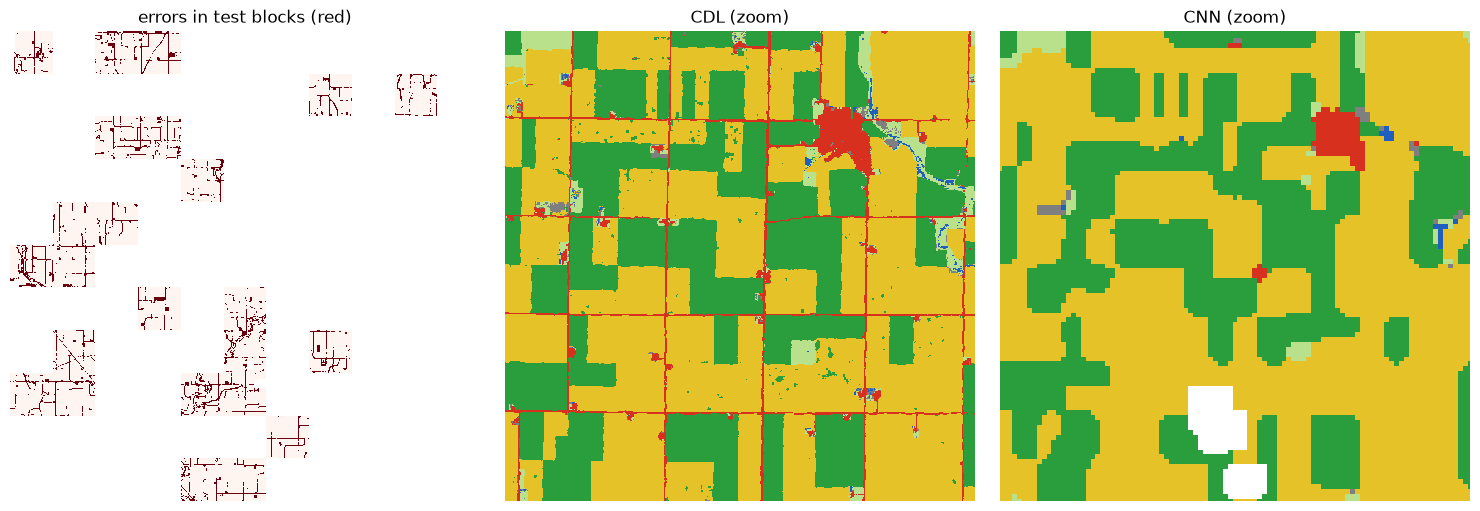

error rate within 3 px of a CDL field boundary: 0.380 | in field interiors: 0.007


In [22]:
err = np.where(m, (pred != ref_l).astype(float), np.nan)  # 1 = wrong, 0 = right, NaN = not tested
zoom = (slice(256 * 2, 256 * 5), slice(256 * 2, 256 * 5))  # a 3 x 3-block zoom
fig, ax = plt.subplots(1, 3, figsize=(15, 5))  # three panels
# errors
ax[0].imshow(err, cmap="Reds", vmin=0, vmax=1, interpolation="nearest"); ax[0].set_title("errors in test blocks (red)")
# CDL zoom
ax[1].imshow(sh(ref_l)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL (zoom)")
# CNN zoom
ax[2].imshow(sh(pred)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("CNN (zoom)")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw
edge = np.zeros_like(ref_l, bool)  # field boundaries in the CDL
# pixels whose neighbour has another class
edge[1:-1, 1:-1] = (ref_l[1:-1, 1:-1] != ref_l[:-2, 1:-1]) | (ref_l[1:-1, 1:-1] != ref_l[2:, 1:-1]) | (ref_l[1:-1, 1:-1] != ref_l[1:-1, :-2]) | (ref_l[1:-1, 1:-1] != ref_l[1:-1, 2:])
from scipy.ndimage import binary_dilation  # grow a 3-pixel band around them
near = binary_dilation(edge, iterations=3)  # boundary zone
# error rate near boundaries and inside fields
print(f"error rate within 3 px of a CDL field boundary: {(pred[m & near] != ref_l[m & near]).mean():.3f} | in field interiors: {(pred[m & ~near] != ref_l[m & ~near]).mean():.3f}")

## Summary of the experiments


In [23]:
best_arch = arch_res["test acc"].idxmax()  # the best architecture
print("Architectures (1 seed, plain CE):")  # header
# architectures sorted by test accuracy
print(arch_res[["parameters", "sec/epoch", "best val acc", "test acc"]].sort_values("test acc", ascending=False).to_string())
print("\nAblations on ResNet-18 (mean ± SD over", len(SEEDS), "seeds):")  # header
print(tab[["test_acc", "test_sd", "macro_f1", "macro_f1_sd"]].to_string())  # the ablation table
# the final model
print(f"\nFinal ResNet-18 ({best_cfg}): chip OA {rep['overall_accuracy']:.4f} (TTA), macro-F1 {rep['macro_f1']:.4f}; map pixel OA on test blocks {oa_px:.4f}")

Architectures (1 seed, plain CE):
                 parameters  sec/epoch  best val acc  test acc
arch                                                          
simple_cnn            17958     0.6649        0.9942    0.9993
vgg_small            290246     0.7857        0.9946    0.9991
efficientnet_b0     4017250     2.6110        0.9915    0.9989
resnet34           21309702     1.8291        0.9926    0.9984
resnet18           11201542     1.2140        0.9939    0.9984
lenet                 62716     0.9252        0.9908    0.9982
swin_t             27534720     5.2600        0.9921    0.9980
convnext_tiny      27835494     2.7267        0.9928    0.9977
vit_b_16           87032070     4.9940        0.9888    0.9948

Ablations on ResNet-18 (mean ± SD over 3 seeds):
                         test_acc  test_sd  macro_f1  macro_f1_sd
config                                                           
baseline (CE)              0.9983   0.0005    0.9652       0.0218
+ OverheadAugment        

## Interpretation, caveats and recommended recipe

* **The chip-level task is nearly saturated.** Every architecture, from the 18 k-parameter `simple_cnn` to the 87 M-parameter ViT, reaches a test accuracy above 0.996. Corn vs. soybeans in large, pure chips (purity $\ge 0.6$, median 0.92) is easy in mid/late-August Sentinel-2 imagery, and CDL itself is a classification product. Differences between architectures are therefore of the order of a few chips and **not meaningful**; cost is the real discriminator (ResNet-18/VGG-style: about 1 s per epoch, ViT/Swin: about 5-6 s) and the small CNNs are as good as the transformers. Transformers are not favoured at this chip size (4 tokens for ViT-B/16).
* **Ablations mostly show up in macro-F1, not accuracy.** Accuracy is dominated by corn and soybeans; the rare classes (grass, developed, wetland, other: under 3 % of chips) are what change. Augmentation and CutMix helped most on macro-F1 and made runs more consistent across seeds (smaller SD); class weights and focal loss did not beat plain CE here. The test blocks contain very few rare-class chips (see the split table: e.g. 1 developed and 0 "other" chip), so the rare-class F1 values and their bootstrap intervals are **unreliable**; accuracy of the rare classes needs a larger or stratified test set.
* **Chip accuracy overstates map quality.** The pixel-wise evaluation of the wall-to-wall map against the original 10 m CDL on the same test blocks gives an accuracy of about 0.88, far below the chip accuracy. Errors concentrate at field boundaries (about 38 % error within 3 px of a CDL boundary against under 1 % in field interiors): a 32 px chip classifier assigns one label to 320 m $\times$ 320 m, so it cannot reproduce field edges, small features (roads, farmsteads) or the thin rare classes. For field-level detail use a segmentation network (U-Net, DeepLab; see the next chapter) or combine the chip map with object boundaries.
* **Validity limits.** One scene, one date, one 30 km AOI, test blocks from the same scene (spatial but not temporal/geographic hold-out); CDL is a model output, not ground truth. Use `Normalizer` fitted on training data only and evaluate on a new region/year before claiming a transferable model (as in the previous notebook's outside-AOI test).

**Recipe that follows from this data:** a small CNN (`simple_cnn`, `vgg_small` or `resnet18`) + `OverheadAugment` + CutMix + AdamW/cosine + AMP + early stopping on validation accuracy, with TTA at inference and a pixel-level check against the reference map.
